In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from sklearn.model_selection import train_test_split

data_folder = "./data/"

In [2]:
import os

os.getcwd()

'c:\\Users\\laura\\Documents\\GitHub\\Testy-Magisterka'

In [3]:
np.random.seed(101)

# Logistic Growth Model

The logistic ODE is defined as:$$\frac{dL(t)}{dt} = a L(t) - b L(t)^2$$Here, $L(t)$ represents the population or labor size, $a$ is the intrinsic growth rate, and $b$ represents the competition or carrying capacity parameter (Jo et al., 2024).

### Parameter Space

<ul>
  <li>Intrinsic growth rate ($a$): $[0.1, 0.6]$</li>
  <li>Competition parameter ($b$): $[0.001, 0.01]$</li>
  <li>Initial population size ($L(0)$): $[5.0, 50.0]$</li>
</ul>

In [4]:
def logistic_ode(t, L, a, b):
    """
    Defines the continuous Logistic Growth ODE.
    dL/dt = a * L - b * L^2
    """
    dL_dt = a * L - b * (L ** 2)
    return dL_dt

def generate_logistic_dataset_with_grid(num_samples=500, T=50, num_steps=100):
    t_eval = np.linspace(0.0, T, num_steps)
    X_params = []
    Y_trajectories = []
    
    np.random.seed(42)
    for _ in range(num_samples):
        a = np.random.uniform(0.1, 0.6)
        b = np.random.uniform(0.001, 0.01)
        L0 = np.random.uniform(5.0, 50.0)
        
        sol = solve_ivp(logistic_ode, (0, T), [L0], args=(a, b), t_eval=t_eval, method='RK45')
        
        X_params.append([L0, a, b])
        Y_trajectories.append(sol.y[0])
        
    X_params = np.array(X_params)
    Y_trajectories = np.array(Y_trajectories)
    
    t_grid_matrix = np.tile(t_eval, (num_samples, 1))
    
    full_data = np.concatenate([X_params, t_grid_matrix, Y_trajectories], axis=1)
    
    # Etykiety
    labels = (['L0_initial', 'growth_rate_a', 'competition_coeff_b'] + 
              [f't_grid_{i}' for i in range(num_steps)] + 
              [f'L_t{i}' for i in range(num_steps)])
    
    return pd.DataFrame(full_data, columns=labels)

In [5]:
df_logistic = generate_logistic_dataset_with_grid(num_samples=500)
train_df, test_df = train_test_split(df_logistic, test_size=0.2, random_state=42)

train_df.to_csv(f'{data_folder}logistic_growth_train.csv', index=False)
test_df.to_csv(f'{data_folder}logistic_growth_test.csv', index=False)

In [6]:
df_logistic.columns

Index(['L0_initial', 'growth_rate_a', 'competition_coeff_b', 't_grid_0',
       't_grid_1', 't_grid_2', 't_grid_3', 't_grid_4', 't_grid_5', 't_grid_6',
       ...
       'L_t90', 'L_t91', 'L_t92', 'L_t93', 'L_t94', 'L_t95', 'L_t96', 'L_t97',
       'L_t98', 'L_t99'],
      dtype='object', length=203)

# The Ramsey-Cass-Koopmans (RCK) Growth System

3. The Ramsey-Cass-Koopmans (RCK) Growth System The RCK model consists of a coupled system of two ODEs that jointly determine consumption and capital accumulation paths.

$$\dot{k}(t) = f(k(t)) - c(t) - (n + g + \delta)k(t)$$
$$\dot{c}(t) = \frac{c(t)}{\theta} [f'(k(t)) - \delta - \rho - \theta g]$$

Variables: $k(t)$ is the capital per effective worker, $c(t)$ is the consumption per effective worker, $\rho$ is the discount rate, $\theta$ is the coefficient of relative risk aversion, and $g$ is the technological growth rate.

The RCK model is a system of two coupled ordinary differential equations that endogenizes the savings rate through representative household optimization (Wikipedia, 2026). The continuous dynamic system is defined as:  

$$\dot{k}(t) = f(k(t)) - c(t) - (n + g + \delta)k(t)$$

$$\dot{c}(t) = \frac{c(t)}{\theta} [f'(k(t)) - \delta - \rho - \theta g]$$

Here, $k(t)$ is the capital per effective worker, $c(t)$ is the consumption per effective worker, $\alpha$ is the capital share of output, $\rho$ is the rate of time preference, $\theta$ is the inverse of the intertemporal elasticity of substitution, $\delta$ is the depreciation rate, $n$ is the population growth rate, and $g$ is the technological growth rate (Haase, 2025).

Parameter and Initial State SpaceBecause the RCK model exhibits saddle-path stability, trajectories that do not converge will diverge or lead to negative values (MathWorks, 2026). To ensure stable numerical solutions, the initial states $k(0)$ and $c(0)$ are sampled within the neighborhood of the steady state $(k^*, c^*)$.

$$\text{Steady State Capital: } k^* = \left( \frac{\alpha}{\delta + \rho + \theta g} \right)^{\frac{1}{1-\alpha}}$$

$$\text{Steady State Consumption: } c^* = (k^*)^{\alpha} - (n + g + \delta)k^*$$

The bounds used for generating the random parameters are as follows:
- Capital elasticity ($\alpha$): $[0.3, 0.4]$
- Depreciation rate ($\delta$): $[0.03, 0.08]$
- Time preference rate ($\rho$): $[0.01, 0.05]$
- Risk aversion parameter ($\theta$): $[1.5, 3.0]$
- Population growth rate ($n$): $[0.01, 0.03]$
- Technological growth rate ($g$): $[0.01, 0.03]$
- Initial conditions $(k_0, c_0)$  $[0.8k^*, 1.2k^*]$ and $[0.8c^*, 1.2c^*]$.

In [7]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from sklearn.model_selection import train_test_split

def rck_ode(t, z, alpha, delta, rho, theta, n, g):
    k, c = z
    f_k = k ** alpha
    f_prime = alpha * (k ** (alpha - 1))
    dk_dt = f_k - c - (n + g + delta) * k
    dc_dt = (c / theta) * (f_prime - delta - rho - theta * g)
    return [dk_dt, dc_dt]

def generate_rck_dataset_with_grid(num_samples=500, T=20, num_steps=100):
    t_eval = np.linspace(0.0, T, num_steps)
    X_inputs = []
    Y_k = []
    Y_c = []
    
    np.random.seed(42)
    while len(X_inputs) < num_samples:
        alpha = np.random.uniform(0.3, 0.4)
        delta = np.random.uniform(0.03, 0.08)
        rho = np.random.uniform(0.01, 0.05)
        theta = np.random.uniform(1.5, 3.0)
        n = np.random.uniform(0.01, 0.03)
        g = np.random.uniform(0.01, 0.03)
        
        try:
            k_star = ((alpha) / (delta + rho + theta * g)) ** (1 / (1 - alpha))
            c_star = (k_star ** alpha) - (n + g + delta) * k_star
            if k_star <= 0 or c_star <= 0: continue
        except (ZeroDivisionError, ValueError): continue
            
        k0 = np.random.uniform(0.8 * k_star, 1.2 * k_star)
        c0 = np.random.uniform(0.8 * c_star, 1.2 * c_star)
        
        sol = solve_ivp(rck_ode, (0, T), [k0, c0], args=(alpha, delta, rho, theta, n, g), 
                        t_eval=t_eval, method='RK45')
        
        if sol.success and sol.y.shape[1] == num_steps:
            if np.max(sol.y) < 1e4 and np.min(sol.y) > 0:
                X_inputs.append([alpha, delta, rho, theta, n, g, k0, c0])
                Y_k.append(sol.y[0])
                Y_c.append(sol.y[1])
                
    X_params = np.array(X_inputs)
    t_grid_matrix = np.tile(t_eval, (num_samples, 1))
    

    full_data = np.concatenate([X_params, t_grid_matrix, np.array(Y_k), np.array(Y_c)], axis=1)
    
    labels = (['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial'] + 
              [f't_grid_{i}' for i in range(num_steps)] + 
              [f'k_t{i}' for i in range(num_steps)] + 
              [f'c_t{i}' for i in range(num_steps)])
    
    return pd.DataFrame(full_data, columns=labels)


In [8]:
# Zapis danych
df_rck = generate_rck_dataset_with_grid(num_samples=2000)
train_df, test_df = train_test_split(df_rck, test_size=0.2, random_state=42)
train_df.to_csv(f'{data_folder}rck_growth_train.csv', index=False)
test_df.to_csv(f'{data_folder}rck_growth_test.csv', index=False)

C:\Users\laura\AppData\Local\Temp\ipykernel_8940\2172263808.py:8: RuntimeWarning: invalid value encountered in scalar power
  f_k = k ** alpha
C:\Users\laura\AppData\Local\Temp\ipykernel_8940\2172263808.py:9: RuntimeWarning: invalid value encountered in scalar power
  f_prime = alpha * (k ** (alpha - 1))


In [ ]:
print(train_df.shape)
print(test_df.shape)

In [9]:
df_rck.columns

Index(['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial',
       't_grid_0', 't_grid_1',
       ...
       'c_t90', 'c_t91', 'c_t92', 'c_t93', 'c_t94', 'c_t95', 'c_t96', 'c_t97',
       'c_t98', 'c_t99'],
      dtype='object', length=308)

# Burger's equation

The Burgers' equation is a nonlinear partial differential equation commonly used as a simplified model for fluid dynamics, turbulence, shock wave formation, and nonlinear transport phenomena. It combines nonlinear convection with diffusion and is frequently used as a benchmark problem in numerical analysis and machine learning for PDEs.

The one-dimensional viscous Burgers' equation is given by:

$$\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}$$

where:
- $u(x,t)$ is the solution field,
- $x$ denotes the spatial coordinate,
- $t$ denotes time,
- $\nu$ is the viscosity coefficient.

In this dataset, the initial condition is defined as:

$$u(x,0)=A\sin(k\pi x)$$

where:
- $A$ controls the amplitude,
- $k$ controls the frequency of the initial wave.

The equation is solved numerically on a discretized space-time grid using a finite difference scheme.

In [37]:
def solve_burgers(A, k, nu, Nx=64, Nt=1000, T=1.0):
    x = np.linspace(0, 1, Nx)
    dx = x[1] - x[0]

    t = np.linspace(0, T, Nt)
    dt = t[1] - t[0]

    u = A * np.sin(k * np.pi * x)

    U = np.zeros((Nt, Nx))
    U[0] = u.copy()

    for n in range(1, Nt):

        u_new = u.copy()

        # periodic copies
        u_left = np.roll(u, 1)
        u_right = np.roll(u, -1)

        # convection (upwind-ish)
        convection = u * (u - u_left) / dx

        # diffusion
        diffusion = nu * (u_right - 2*u + u_left) / dx**2

        u_new = u - dt * convection + dt * diffusion

        # Dirichlet BC
        u_new[0] = 0
        u_new[-1] = 0

        # safety clip
        if np.any(np.isnan(u_new)) or np.any(np.isinf(u_new)):
            raise ValueError("Numerical instability detected")

        u = u_new
        U[n] = u.copy()

    return x, t, U


def generate_burgers_dataset(num_samples=500, Nx=64, Nt=100, T=1.0):
    np.random.seed(42)

    X_params = []
    X_grid = []
    Y_solutions = []

    for _ in range(num_samples):
        # Parametry
        A = np.random.uniform(0.5, 1.2)
        k = np.random.randint(1,2)
        nu = np.random.uniform(0.02,0.05)

        # Rozwiązanie PDE
        x, t, U = solve_burgers(A, k, nu, Nx=Nx, Nt=Nt, T=T)

        # Flatten siatek
        x_grid = np.tile(x, Nt)
        t_grid = np.repeat(t, Nx)

        # Flatten rozwiązania
        U_flat = U.flatten()

        # Parametry wejściowe
        params = [A, k, nu]

        # Zapis
        X_params.append(params)
        X_grid.append(np.concatenate([x_grid, t_grid]))
        Y_solutions.append(U_flat)

    X_params = np.array(X_params)
    X_grid = np.array(X_grid)
    Y_solutions = np.array(Y_solutions)

    # Final dataset
    full_data = np.concatenate([X_params, X_grid, Y_solutions], axis=1)

    # Nazwy kolumn
    labels = (
        ['A_initial', 'frequency_k', 'viscosity_nu']
        +
        [f'x_grid_{i}' for i in range(Nx * Nt)]
        +
        [f't_grid_{i}' for i in range(Nx * Nt)]
        +
        [f'u_{i}' for i in range(Nx * Nt)]
    )

    return pd.DataFrame(full_data, columns=labels)

In [48]:
df_burgers = generate_burgers_dataset(num_samples=500, Nx=32, Nt=500)
train_df, test_df = train_test_split(df_burgers, test_size=0.2, random_state=42)

train_df.to_csv(f"{data_folder}burgers_train.csv", index=False)
test_df.to_csv(f"{data_folder}burgers_test.csv", index=False)

In [49]:
print(train_df.shape)
print(test_df.shape)

(400, 48003)
(100, 48003)


In [52]:
train_df.columns

Index(['A_initial', 'frequency_k', 'viscosity_nu', 'x_grid_0', 'x_grid_1',
       'x_grid_2', 'x_grid_3', 'x_grid_4', 'x_grid_5', 'x_grid_6',
       ...
       'u_15990', 'u_15991', 'u_15992', 'u_15993', 'u_15994', 'u_15995',
       'u_15996', 'u_15997', 'u_15998', 'u_15999'],
      dtype='object', length=48003)

-0.9996891820008162 0.9996891820008162


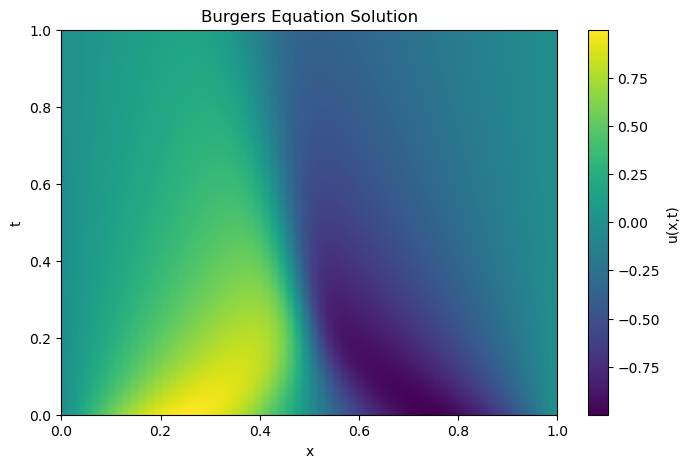

In [50]:
import matplotlib.pyplot as plt

# Wygeneruj jedną próbkę
x, t, U = solve_burgers(A=1.0, k=2, nu=0.02, Nx=64, Nt=1000)
print(U.min(), U.max())

plt.figure(figsize=(8,5))

plt.imshow(U, aspect='auto', origin='lower', extent=[x.min(), x.max(), t.min(), t.max()])

plt.colorbar(label='u(x,t)')
plt.xlabel('x')
plt.ylabel('t')
plt.title("Burgers Equation Solution")

plt.show()

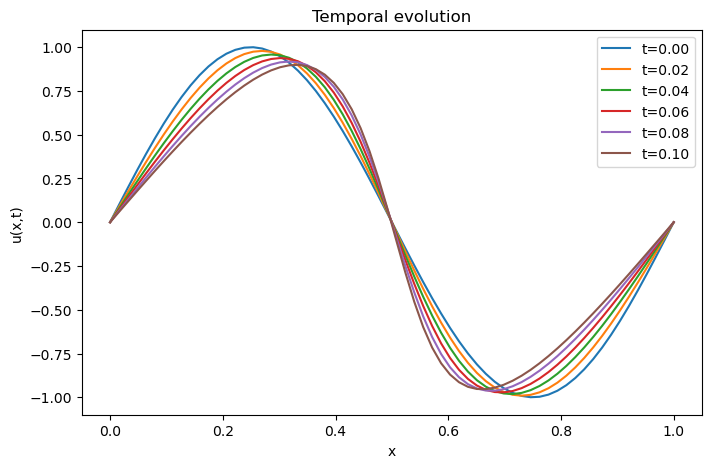

In [51]:
plt.figure(figsize=(8,5))

times_to_plot = [0, 20, 40, 60, 80, 99]

for idx in times_to_plot:
    plt.plot(x, U[idx], label=f"t={t[idx]:.2f}")

plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.title("Temporal evolution")
plt.legend()

plt.show()

In [ ]:
#### nie wiem nie dziala mi animacja na VSC??

# from matplotlib.animation import FuncAnimation

# fig = plt.figure()
# axis = plt.axes(ylim=(U.min(), U.max()))
# line, = axis.plot(x, U[0])

# def init(): 
#     line.set_data([], []) 
#     return line, 

# def update(frame):
#     line.set_ydata(U[frame])
#     axis.set_title(f"t = {t[frame]:.2f}")
#     return line,

# anim = FuncAnimation(fig, update, frames=len(t), interval=50)

# # anim.save('BurgersEquation.mp4', writer = 'ffmpeg', fps = 30)
# plt.show()